## **PART A**


In [3]:
from google.colab import files

uploaded = files.upload()

Saving prepared_chunks.jsonl to prepared_chunks.jsonl


In [4]:

!pip install -q langchain-core

import json
import pickle
from langchain_core.documents import Document

prepared_records = []

with open('/content/prepared_chunks.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            prepared_records.append(json.loads(line))

chunks = [
    Document(
        page_content=record['text'],
        metadata=record['metadata']
    )
    for record in prepared_records
]

with open('/content/chunks.pkl', 'wb') as f:
    pickle.dump(chunks, f)

print('Total prepared records:', len(prepared_records))
print('Total compatibility chunks:', len(chunks))
print('Successfully created chunks.pkl')


Total prepared records: 3
Total compatibility chunks: 3
Successfully created chunks.pkl


In [5]:

# Cell 1 — Topic 4 setup and Topic 3 hand-off verification

!pip install -q pandera pandas matplotlib

import os, re, json, pickle, hashlib

import pandas as pd

import matplotlib.pyplot as plt

import pandera.pandas as pa

with open('/content/chunks.pkl', 'rb') as f:
    chunks = pickle.load(f)

prepared_records = []

with open('/content/prepared_chunks.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            prepared_records.append(json.loads(line))

print(f'Compatibility chunks: {len(chunks)}')

print(f'Inspectable JSONL records: {len(prepared_records)}')

if len(chunks) != len(prepared_records):
    raise ValueError('Topic 3 hand-off mismatch: JSONL and PKL chunk counts differ.')

print('Topic 3 hand-off verified.')

print(chunks[0].page_content[:250])

print(chunks[0].metadata)


Compatibility chunks: 3
Inspectable JSONL records: 3
Topic 3 hand-off verified.
New Malaysia Ambient Air Quality Standard 
New Ambient Air Quality Standard was established in order to replace the older Malaysia Ambient Air Quality Guideline 
that has been used since 1989. 
The New Ambient Air Quality Standard adopts 6 air pollut
{'record_id': 'Air-Quality-Standard-BI-0001', 'source': 'Air-Quality-Standard-BI.pdf', 'source_sha256': 'b7453d84a6e72955787e6f4afa9eb8290f6bfedd307d805845355ddebf349e81', 'processing': 'paragraph-aware-char-500', 'page': None}


In [6]:
from google.colab import files

files.download('/content/chunks.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

# Cell 2 — Build a chunk-quality inventory

rows = []

for i, chunk in enumerate(chunks):
    text = chunk.page_content or ''
    meta = chunk.metadata or {}
    source = str(meta.get('source', '') or '')
    stripped = text.strip()

    rows.append({
        'chunk_id': i,
        'source': source,
        'page': meta.get('page', None),
        'text': text,
        'char_count': len(stripped),
        'missing_text': len(stripped) == 0,
        'missing_source': source.strip() == '',
        'corrupted_char': ('\x00' in text) or ('�' in text),
        'noisy_whitespace': bool(re.search(r'\n{4,}| {4,}', text)),

        # AirAware AI project-specific check
        'expected_doe_source': os.path.basename(source) in [
            'Air-Quality-Standard-BI.pdf',
            'Air-Quality-Standard-BI (2).pdf',
            'doe_api_information.txt'
        ]
    })

df = pd.DataFrame(rows)

print(df[['chunk_id', 'source', 'page', 'char_count',
          'missing_text', 'missing_source',
          'corrupted_char', 'noisy_whitespace',
          'expected_doe_source']].head())

print(df['char_count'].describe())

print('Missing text:', int(df['missing_text'].sum()))

print('Missing source metadata:', int(df['missing_source'].sum()))

print('Possible corrupted text:', int(df['corrupted_char'].sum()))

print('Possible noisy whitespace:', int(df['noisy_whitespace'].sum()))

print('Unexpected DOE sources:', int((~df['expected_doe_source']).sum()))


   chunk_id                       source  page  char_count  missing_text  \
0         0  Air-Quality-Standard-BI.pdf  None         500         False   
1         1  Air-Quality-Standard-BI.pdf  None         499         False   
2         2  Air-Quality-Standard-BI.pdf  None         452         False   

   missing_source  corrupted_char  noisy_whitespace  expected_doe_source  
0           False           False             False                 True  
1           False           False             False                 True  
2           False           False             False                 True  
count      3.000000
mean     483.666667
std       27.428695
min      452.000000
25%      475.500000
50%      499.000000
75%      499.500000
max      500.000000
Name: char_count, dtype: float64
Missing text: 0
Missing source metadata: 0
Possible corrupted text: 0
Possible noisy whitespace: 0
Unexpected DOE sources: 0


# **A2 — Project-Specific Quality Check**

The AirAware AI project includes an additional validation field named `expected_doe_source` to check whether each prepared text chunk originates from an expected Department of Environment (DOE) dataset filename.

This check supports FR4 and RAI1 by helping identify unexpected sources and potential provenance issues. It also supports data consistency and traceability.

Any unexpected source will be flagged for manual review before being accepted into the prepared dataset.

In [8]:

# Cell 3 — Manual inspection

sample = df.sample(min(10, len(df)), random_state=42)

for idx in sample['chunk_id']:
    c = chunks[int(idx)]
    print('\n --- CHUNK', idx, '---')
    print('Source:', c.metadata.get('source','?'),
          '| Page:', c.metadata.get('page','?'))
    print(c.page_content[:1200])



 --- CHUNK 0 ---
Source: Air-Quality-Standard-BI.pdf | Page: None
New Malaysia Ambient Air Quality Standard 
New Ambient Air Quality Standard was established in order to replace the older Malaysia Ambient Air Quality Guideline 
that has been used since 1989. 
The New Ambient Air Quality Standard adopts 6 air pollutants criteria that include 5 existing air pollutants which are 
particulate matter with the size of less than 10 micron (PM10), sulfur dioxide (SO2), carbon monoxide (CO), nitrogen 
dioxide (NO2), and ground level ozone (O3) as well as 1 additional p

 --- CHUNK 1 ---
Source: Air-Quality-Standard-BI.pdf | Page: None
arameter which is particulate matter with the size of 
less than 2.5 micron (PM2.5). 
The air pollutants concentration limit will be strengthen in stages until 2020. There are 3 interim targets set which include 
interim target 1 (IT-1) in 2015, interim target 2 (IT-2) in 2018 and the full implementation of the standard in 2020. 
Table 1 : New Malaysia Ambient Ai

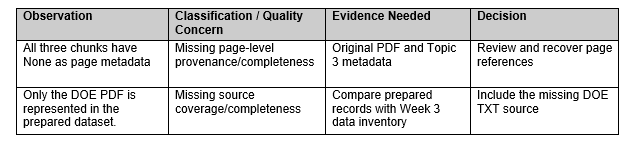

# **REFLECTION**

During manual inspection, I identified that the word “parameter” was split between two chunks due to the 500-character chunking method. This affects data completeness and consistency because splitting words may reduce the clarity of the extracted information and affect semantic retrieval.

Automated checks may not detect this issue because both chunks contain valid text, meet the character length requirements and contain no corrupted characters. Manual inspection is necessary to identify broken words and incomplete context.

In [9]:

# Cell 4 — Repeatable validation rules

schema = pa.DataFrameSchema({

    'chunk_id': pa.Column(
        int, checks=pa.Check.ge(0), nullable=False),

    'source': pa.Column(str,
        checks=pa.Check(
            lambda s: s.str.strip().str.len() > 0,
            error='source metadata must not be empty'),
        nullable=False),

    'text': pa.Column(str,
        checks=pa.Check(
            lambda s: s.str.strip().str.len() > 0,
            error='chunk text must not be empty'),
        nullable=False),

    'char_count': pa.Column(int,
        checks=pa.Check.ge(100),
        nullable=False),

    'corrupted_char': pa.Column(bool,
        checks=pa.Check(
            lambda s: ~s,
            error='garbled/replacement characters found'),
        nullable=False),

    # AirAware AI project-specific rule
    'expected_doe_source': pa.Column(bool,
        checks=pa.Check(
            lambda s: s,
            error='unexpected DOE source filename'),
        nullable=False),

}, strict=False)

try:
    schema.validate(df, lazy=True)
    failure_cases = pd.DataFrame()
    print('All schema rules passed.')

except pa.errors.SchemaErrors as exc:
    failure_cases = exc.failure_cases.copy()
    print(failure_cases[[
        'schema_context', 'column', 'check',
        'failure_case', 'index'
    ]])
    print(f'Validation failures: {len(failure_cases)}')

# Save evidence for the report

os.makedirs('/content/docs', exist_ok=True)

failure_cases.to_csv(
    '/content/docs/week4_validation_failures.csv',
    index=False
)


All schema rules passed.


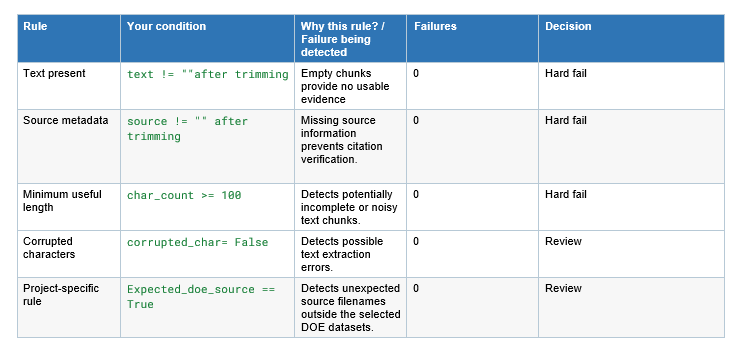

The minimum threshold of 100 characters is used to identify potentially incomplete text chunks, extraction artefacts or insufficient contextual information. This supports FR3 and NFR3 by helping identify chunks that may not contain enough useful information for RAG and semantic retrieval.

However, a chunk containing fewer than 100 characters may still provide valid information. Therefore, the threshold is treated as a warning that requires manual review rather than automatic removal.

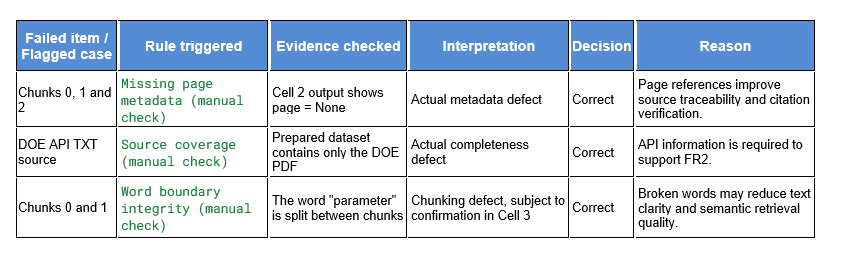

## **PART B**

In [10]:

# Cell 5 — Exact hash deduplication with provenance preserved

seen = {}
unique_chunks = []
duplicate_records = []

for chunk in chunks:
    normalized = re.sub(r'\s+', ' ', chunk.page_content.strip())
    h = hashlib.sha256(normalized.encode('utf-8')).hexdigest()

    if h not in seen:
        seen[h] = {
            'metadata': chunk.metadata.copy(),
            'sources': [chunk.metadata.get('source', '?')]
        }
        unique_chunks.append(chunk)

    else:
        seen[h]['sources'].append(chunk.metadata.get('source', '?'))
        duplicate_records.append({
            'hash': h,
            'duplicate_source': chunk.metadata.get('source', '?'),
            'first_source': seen[h]['sources'][0],
            'preview': normalized[:160]
        })

print('Before:', len(chunks))
print('After exact deduplication:', len(unique_chunks))
print('Exact duplicates found:', len(duplicate_records))

os.makedirs('/content/docs', exist_ok=True)
os.makedirs('/content/data', exist_ok=True)

pd.DataFrame(duplicate_records).to_csv(
    '/content/docs/week4_duplicate_review.csv', index=False)

with open('/content/data/chunks_clean.pkl', 'wb') as f:
    pickle.dump(unique_chunks, f)

with open('/content/data/prepared_chunks_clean.jsonl', 'w', encoding='utf-8') as f:
    for i, c in enumerate(unique_chunks):
        record = {
            'chunk_id': i,
            'text': c.page_content,
            'metadata': c.metadata
        }
        f.write(json.dumps(record, ensure_ascii=False) + '\n')

print('Saved cleaned PKL and inspectable JSONL outputs.')


Before: 3
After exact deduplication: 3
Exact duplicates found: 0
Saved cleaned PKL and inspectable JSONL outputs.


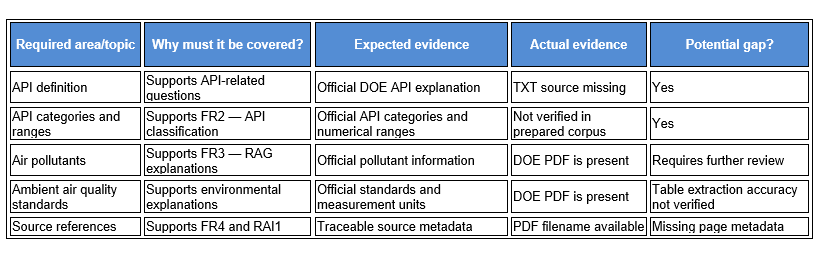

                     source  chunks  percent
Air-Quality-Standard-BI.pdf       3    100.0


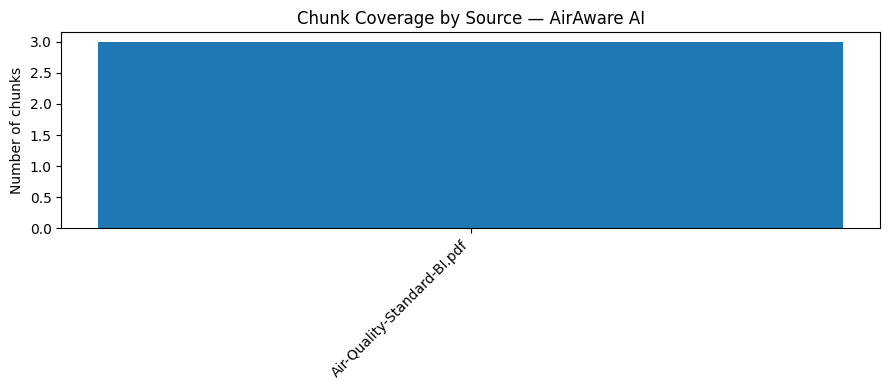

In [11]:

# Cell 6 — Coverage by source

from collections import Counter

source_counts = Counter(
    c.metadata.get('source', 'unknown') for c in unique_chunks
)

coverage = pd.DataFrame([
    {'source': src, 'chunks': cnt, 'percent': cnt/len(unique_chunks)*100}
    for src, cnt in source_counts.items()
]).sort_values('chunks', ascending=False)

print(coverage.to_string(index=False))

plt.figure(figsize=(9,4))
plt.bar(coverage['source'].astype(str), coverage['chunks'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of chunks')
plt.title('Chunk Coverage by Source — AirAware AI')
plt.tight_layout()
plt.savefig('/content/docs/week4_coverage_by_source.png')
plt.show()


In [12]:

# AirAware AI — Domain-specific coverage

topics = {
    'API information': [
        'air pollutant index', 'unhealthy', 'hazardous'
    ],
    'Air pollutants': [
        'pm2.5', 'pm10', 'ozone', 'sulphur dioxide',
        'nitrogen dioxide', 'carbon monoxide'
    ],
    'Air quality standards': [
        'ambient air quality standard', 'concentration'
    ],
    'Health precautions': [
        'precaution', 'health advice', 'outdoor activities'
    ]
}

topic_rows = []

for topic, keywords in topics.items():
    count = sum(
        any(keyword.lower() in c.page_content.lower()
            for keyword in keywords)
        for c in unique_chunks
    )

    topic_rows.append({
        'topic': topic,
        'matching_chunks': count
    })

topic_coverage = pd.DataFrame(topic_rows)

print(topic_coverage.to_string(index=False))


                topic  matching_chunks
      API information                0
       Air pollutants                3
Air quality standards                2
   Health precautions                0


# **REFLECTION**


The API categories and classification ranges appear to be the least well supported by authoritative evidence. The current prepared dataset contains only the DOE New Malaysia Ambient Air Quality Standard PDF, while the DOE Air Pollutant Index TXT source is missing.

This represents a genuine coverage gap, rather than simply a difference in document or chunk quantity. The missing information may affect FR2, which requires accurate API classification based on official DOE ranges.

To address this gap, the DOE API TXT source should be included, processed and validated before downstream RAG development.

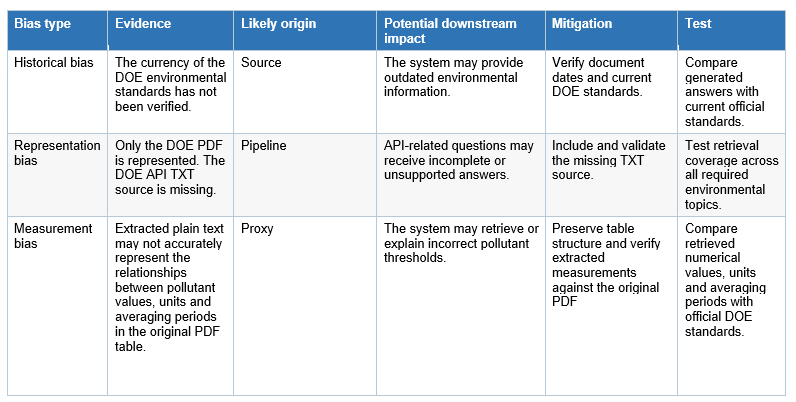


# **REFLECTION**

#### Risk 1: Representation Bias

- **Origin:** Pipeline. The DOE API TXT source is missing
  from the prepared dataset.
- **Affected users/topics:** Users asking about API
  categories, classification ranges and air quality.
- **Propagation:** Missing information may lead to
  incomplete retrieval and unsupported generated answers.
- **Pipeline intervention:** Include the missing TXT
  source and validate source coverage.
- **Topic 8 testing:** Retrieval coverage, API classification
  accuracy, answer correctness and source grounding.

#### Risk 2: Measurement Bias

- **Origin:** Proxy. Extracted text may not accurately
  represent the measurements in the original DOE PDF table.
- **Affected users/topics:** Users asking about pollutant
  concentrations, units and air quality standards.
- **Propagation:** Loss of table structure may lead to
  incorrect numerical values or units in generated answers.
- **Pipeline intervention:** Preserve table structure
  and verify extracted information against the original PDF.
- **Topic 8 testing:** Numerical accuracy, measurement unit
  correctness, retrieval accuracy and citation correctness.


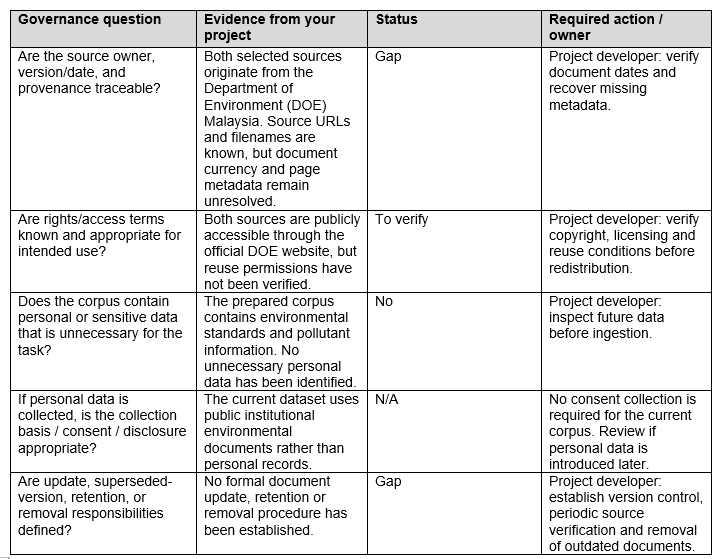